# Reflection From Scratch: Who Should Critique the Code an Agent Writes

**A coding agent implements 12 small tickets from a billing and ops backlog, three times each, and hidden tests grade every function. Then each function gets a second pass from four different critics: the model reviewing its own code, a fresh reviewer told to find faults, the same reviewer made to prove each fault by running it, and the failing tests themselves. This notebook counts what each second pass fixed, what it broke, and what it cost.**

## The one idea

**Reflection** is a second pass over finished work: critique the draft, then revise it against the critique. It can only help as much as the critique tells the model something it did not already know. A model rereading its own code knows exactly what it knew while writing it, so a misread rule survives the review. A failing test knows something the model does not: the call, what came back, and what should have come back, and it is true. So the design question is not whether to reflect but who writes the critique.

Two claims from 2026 make this concrete. Models grade their own work too generously, and a separate reviewer tuned to be skeptical is easier to build than a self-critical writer ([Anthropic, 2026](https://www.anthropic.com/engineering/harness-design-long-running-apps)). And a critic that is not grounded in execution can make results worse than no critic at all ([arXiv 2606.02866](https://arxiv.org/abs/2606.02866)). This notebook tests both on one small job where every answer can be checked exactly.

## Overview

1. Twelve tickets, each with `check` tests a critic may run and `hidden` tests used only for grading
2. A small runner that executes model-written code in a separate process and turns each failure into one readable line
3. One attempt per ticket, three samples each: 36 functions, graded
4. Critic 1: the model reviews its own code, in the same conversation
5. Critic 2: a fresh, skeptical reviewer that reads the code but cannot run it
6. Critic 3: the same reviewer behind an evidence gate, so a finding reaches the reviser only if running it shows the bug
7. Critic 4: the failing check tests, sent back word for word
8. Side by side: fixed, broke, approvals of wrong code, calls and dollars
9. An aside: what "I reviewed it, it is correct" looked like

**Requirements:** `pip install openai matplotlib` and an `OPENAI_API_KEY`. The run makes 365 calls to `gpt-5.4-mini` and cost $0.48 at the list prices of 2026-10-30, in under two minutes. Outputs saved in this notebook come from a real run. Yours will differ, because the model is not deterministic; section 8 gives the spread across this run and two earlier ones.

> 📖 This notebook is the hands-on side of Chapter 19, "Reflection and Self-Correction", of [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-agents-tutorials--reflection-from-scratch&click=book-nb-agents-top&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2%3Fmaas%3Dmaas_adg_api_580351185840460851_static_9_573%26ref_%3Daa_maas%26tag%3Dmaas%26aa_campaignid%3Dagents-en%26aa_adgroupid%3Dgithub-notebook%26aa_creativeid%3Dgenai-reflection-top&retarget=0&text=book-nb-agents-top), by the author of this repository.

In [1]:
# !pip install openai matplotlib
import os, sys, json, re, time, subprocess
from concurrent.futures import ThreadPoolExecutor
from datetime import date
import openai
import matplotlib.pyplot as plt

MODEL = "gpt-5.4-mini"
# USD per 1M tokens, from https://developers.openai.com/api/docs/pricing on 2026-10-30. Check yours.
PRICE = {"input": 0.75, "cached_input": 0.075, "output": 4.50}
client = openai.OpenAI()          # reads OPENAI_API_KEY from the environment
USAGE = []                        # one row per model call: (arm, input tokens, cached input tokens, output tokens)
T0 = time.time()

def chat(messages, arm, schema=None):
    # reasoning_effort="none" is this model's default (no hidden reasoning); it is set here so a new default cannot change the run
    kwargs = {"model": MODEL, "messages": messages, "reasoning_effort": "none"}
    if schema:
        kwargs["response_format"] = {"type": "json_schema", "json_schema": {"name": "out", "strict": True, "schema": schema}}
    for attempt in range(5):
        try:
            reply = client.chat.completions.create(**kwargs)
            break
        except (openai.RateLimitError, openai.APIConnectionError, openai.InternalServerError):
            if attempt == 4: raise
            time.sleep(5 * (attempt + 1))
    u = reply.usage
    cached = (u.prompt_tokens_details.cached_tokens or 0) if u.prompt_tokens_details else 0
    USAGE.append((arm, u.prompt_tokens, cached, u.completion_tokens))
    text = reply.choices[0].message.content.strip()
    return json.loads(text) if schema else text

def cost(arm=None):
    rows = [r for r in USAGE if arm is None or r[0] == arm]
    i, c, o = (sum(r[k] for r in rows) for k in (1, 2, 3))
    return len(rows), ((i - c) * PRICE["input"] + c * PRICE["cached_input"] + o * PRICE["output"]) / 1e6

def parallel(fn, items, workers=8):
    # the 36 cases run side by side; the rounds inside one case still run in order
    with ThreadPoolExecutor(workers) as pool:
        return list(pool.map(fn, items))

## 1. A job with a known answer

The backlog: twelve small functions for a billing and operations service, the kind of ticket a coding agent gets every day. Shipping costs, late fees, loyalty points, money parsing, display formatting. Each ticket is a signature and a docstring that lists the rules, usually three to six of them, and several rules interact: a cap that wins over a minimum, a discount applied after a surcharge.

Every ticket comes with two test sets. Their expected values were computed by reference implementations that are not in this notebook:

- `check` tests, about one per rule. A critic is allowed to run these.
- `hidden` tests: different inputs for the same rules. They are only used to grade.

Grading on tests no critic ever saw matters. A revision that special-cases the exact calls it was told about gets no credit unless it also gets the rule right.

In [2]:
# The 12 tickets, exactly as the model sees them
TICKETS = {
"shipping_cents": '''def shipping_cents(weight_g: int, zone: str, express: bool, subtotal_cents: int) -> int:
    """Return the shipping cost of an order in cents.

    1. Zones and prices: "domestic" 500 base + 100 per extra kg; "eu" 1200 base + 250 per extra kg;
       "world" 2000 base + 400 per extra kg. The base price covers the first 1000 g; every started
       kg above that is one extra kg (1001 g is 1 extra kg, 2000 g is 1, 2001 g is 2).
    2. Express doubles the cost.
    3. Domestic orders that are not express ship free when subtotal_cents is 5000 or more.
    4. EU orders with subtotal_cents of 15000 or more get half off the shipping cost, after the express
       doubling; round a half cent down.
    5. Raise ValueError for an unknown zone, or a weight that is not between 1 and 30000 g.
    """''',

"late_fee_cents": '''def late_fee_cents(due: date, paid: date, amount_cents: int) -> int:
    """Return the late fee in cents for an invoice of amount_cents, due on `due` and paid on `paid`.

    1. If `due` falls on a Saturday or Sunday, the due date moves to the following Monday first.
    2. Payment up to 3 days after the due date is on time: no fee.
    3. Otherwise the fee is 2% of the amount for every started week late, counting the days from the
       due date (not from the end of the grace period): 4 to 7 days late is 1 week, 8 days is 2 weeks.
       Round the fee down to a whole cent.
    4. The fee is at least 500 cents, but never more than 20% of the amount (rounded down).
       The 20% cap wins over the 500 minimum: a 1500-cent invoice paid late owes 300.
    """''',

"loyalty_points": '''def loyalty_points(lines: list[tuple[str, int]], tier: str, birthday_month: bool) -> int:
    """Return the loyalty points one order earns. Each line is (sku, amount_cents).

    1. Lines whose sku starts with "GC-" are gift cards: they earn nothing and do not count toward the eligible total.
    2. Base points: 1 point per whole dollar of the eligible total (drop the cents once, on the total, not per line).
    3. Tier multiplier: "bronze" x1, "silver" x1.5, "gold" x2, applied to the base points; round down.
    4. Birthday bonus: add 100 points in the customer's birthday month, but only if the eligible total
       is at least 2000 cents. The bonus is not multiplied.
    5. One order earns at most 5000 points, bonus included.
    6. Raise ValueError for an unknown tier or a negative amount.
    """''',

"format_names": '''def format_names(names: list[str], limit: int = 3) -> str:
    """Format a list of names for a sentence such as "Liked by ...".

    1. Strip spaces around each name, skip empty names, and drop repeated names (compared case-insensitively),
       keeping the first spelling and the original order.
    2. No names: "". One: "Ana". Two: "Ana and Ben". Three or more: "Ana, Ben and Cy" (no comma before "and").
    3. If there are more names than `limit`, show the first `limit` names and then "and N others":
       "Ana, Ben, Cy and 2 others", or "and 1 other" when only one is left.
    """''',

"password_problems": '''def password_problems(pw: str, username: str) -> list[str]:
    """Return the list of policy problems with a password, as codes, in exactly this order:

    "length"   fewer than 12 characters
    "upper"    no uppercase ASCII letter A-Z
    "lower"    no lowercase ASCII letter a-z
    "digit"    no digit 0-9
    "symbol"   no ASCII punctuation character (one of !"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~); a space is not a symbol
    "username" contains the username, compared case-insensitively; only checked when the username has 3 or more characters
    "repeat"   the same character three or more times in a row, such as "aaa" or "111"
    "space"    starts or ends with whitespace
    A password with no problems returns [].
    """''',

"add_months": '''def add_months(d: date, n: int) -> date:
    """Add n calendar months to d (n may be negative or zero).

    1. If d's day does not exist in the target month, use the last day of the target month (Jan 31 + 1 -> Feb 28).
    2. End-of-month rule: if d is the last day of its month, the result is always the last day of the
       target month (Feb 28, 2026 + 1 -> Mar 31, 2026; Apr 30 + 1 -> May 31).
    3. Leap years follow the Gregorian calendar.
    """''',

"human_bytes": '''def human_bytes(n: int) -> str:
    """Format a byte count for people, with 1 KB = 1024 bytes.

    - Below 1024: "<n> B", for example "512 B" (no decimal).
    - Otherwise use the largest unit among KB, MB, GB and TB that leaves a value of at least 1,
      shown with one decimal: "1.5 KB", "3.0 MB".
    - If rounding to one decimal gives 1024.0, use the next unit up instead ("1.0 MB", not "1024.0 KB"),
      unless the unit is already TB, the largest unit.
    - Raise ValueError for a negative n.
    """''',

"split_cents": '''def split_cents(total: int, weights: list[int]) -> list[int]:
    """Split `total` cents (a non-negative int) into shares proportional to `weights`, as whole cents that add up to exactly `total`.

    - First give each share the floor of total * weight / sum(weights).
    - Then hand out the cents left over, one each, to the shares with the largest remainders
      (the fractional part that the floor dropped). On a tie, the earlier share gets its cent first.
    - Raise ValueError if weights is empty, if any weight is negative, or if all weights are 0.
    Example: split_cents(100, [1, 1, 1]) == [34, 33, 33]
    """''',

"parse_money": '''def parse_money(text: str) -> int:
    """Parse a US-dollar amount and return it in cents.

    - Accepted forms: "12", "12.5", "12.50", "$12.50", "1,234.56", "-$3.10", and "($3.10)" (parentheses mean negative).
    - Commas, if used, must group all the whole-dollar digits in threes ("1,234", never "12,34" or "1234,567").
    - A decimal point must be followed by 1 or 2 digits; "12.5" means 1250 cents.
    - Surrounding spaces are ignored. Raise ValueError for anything else, including "" and "$".
    """''',

"parse_duration": '''def parse_duration(text: str) -> int:
    """Parse a duration such as "1h30m", "2d 4h" or "1h 05m 10s" and return it in seconds.

    - Units: d (days), h (hours), m (minutes), s (seconds), in upper or lower case.
    - Each part is digits followed directly by a unit, with no space between them.
    - Spaces between parts are optional; leading and trailing spaces are ignored.
    - Each unit may appear at most once, and units must appear in the order d, h, m, s.
    - Raise ValueError for an empty string, a number with no unit, an unknown unit,
      a repeated unit, or units out of order.
    """''',

"percent_change": '''def percent_change(old: float, new: float) -> str:
    """Return the change from old to new as a percentage string with one decimal and a sign.

    - The change is (new - old) / abs(old) * 100.
    - Round to one decimal, with halves rounded away from zero (6.25 -> 6.3, -6.25 -> -6.3).
    - A positive result gets a "+": "+12.5%". A negative one: "-3.0%".
      Zero, including a value that rounds to zero, is "0.0%" with no sign.
    - If old is 0, return "n/a".
    """''',

"normalize_phone": '''def normalize_phone(text: str) -> str | None:
    """Normalize a North American phone number to the form "+1XXXXXXXXXX", or return None if it is invalid.

    - Ignore spaces, dashes, dots and parentheses.
    - The number may start with the country code "+1" or "1". A "+" anywhere else makes it invalid.
    - After the country code there must be exactly 10 digits.
    - The first and the fourth of those 10 digits (area code and exchange) cannot be 0 or 1.
    - Any other character, such as a letter, makes it invalid.
    """'''
}

In [3]:
# Each test is (arguments, expected result). ValueError means the ticket requires that exception.
# `check` tests may be run by a critic; `hidden` tests are only used to grade.
TESTS = {
    "shipping_cents": {
        "check": [
            ("1000, 'domestic', False, 0", 500), ("2001, 'eu', False, 0", 1700), ("1500, 'world', True, 0", 4800),
            ("500, 'domestic', False, 5000", 0), ("3000, 'eu', True, 15000", 1700),
            ("0, 'eu', False, 0", ValueError), ("100, 'mars', False, 0", ValueError)],
        "hidden": [
            ("1001, 'domestic', False, 4999", 600), ("2000, 'world', False, 0", 2400),
            ("500, 'domestic', True, 9000", 1000), ("30000, 'eu', False, 20000", 4225),
            ("30001, 'world', False, 0", ValueError), ("1999, 'eu', False, 14999", 1450),
            ("4500, 'world', True, 100000", 7200), ("2500, 'eu', True, 15000", 1700)]},
    "late_fee_cents": {
        "check": [
            ('date(2026, 3, 2), date(2026, 3, 5), 10000', 0), ('date(2026, 3, 2), date(2026, 3, 6), 100000', 2000),
            ('date(2026, 3, 2), date(2026, 3, 10), 100000', 4000),
            ('date(2026, 3, 7), date(2026, 3, 12), 100000', 0), ('date(2026, 3, 2), date(2026, 3, 9), 10000', 500),
            ('date(2026, 3, 2), date(2026, 6, 1), 100000', 20000), ('date(2026, 3, 2), date(2026, 3, 9), 1000', 200)],
        "hidden": [
            ('date(2026, 3, 2), date(2026, 2, 20), 50000', 0), ('date(2026, 3, 8), date(2026, 3, 12), 50000', 0),
            ('date(2026, 3, 8), date(2026, 3, 13), 50000', 1000),
            ('date(2026, 3, 2), date(2026, 3, 16), 100000', 4000),
            ('date(2026, 3, 2), date(2026, 3, 17), 123457', 7407),
            ('date(2026, 3, 2), date(2026, 3, 20), 2000', 400), ('date(2026, 3, 2), date(2026, 9, 1), 3333', 666),
            ('date(2026, 3, 2), date(2026, 4, 1), 26000', 2600)]},
    "loyalty_points": {
        "check": [
            ("[('A-1', 1999)], 'bronze', False", 19), ("[('A-1', 1999), ('B-2', 1)], 'bronze', False", 20),
            ("[('A-1', 3300)], 'silver', False", 49), ("[('GC-50', 5000), ('A-1', 1000)], 'gold', False", 20),
            ("[('A-1', 2500)], 'gold', True", 150), ("[('A-1', 300000)], 'gold', False", 5000),
            ("[('A-1', 100)], 'platinum', False", ValueError)],
        "hidden": [
            ("[('A-1', 150), ('A-2', 150), ('A-3', 150)], 'bronze', False", 4),
            ("[('A-1', 1999)], 'gold', True", 38), ("[('GC-1', 5000), ('A-1', 1500)], 'silver', True", 22),
            ("[('A-1', 250000)], 'gold', True", 5000), ("[('A-1', 4100)], 'silver', True", 161),
            ("[], 'bronze', True", 0), ("[('A-1', -5)], 'gold', False", ValueError),
            ("[('gc-9', 1000)], 'bronze', False", 10)]},
    "format_names": {
        "check": [
            ("['Ana']", 'Ana'), ("['Ana', 'Ben']", 'Ana and Ben'), ("['Ana', 'Ben', 'Cy']", 'Ana, Ben and Cy'),
            ("['Ana', 'Ben', 'Cy', 'Dee', 'Eli']", 'Ana, Ben, Cy and 2 others'),
            ("[' Ana ', '', 'ana', 'Ben']", 'Ana and Ben'), ('[]', '')],
        "hidden": [
            ("['Ana', 'Ben', 'Cy', 'Dee']", 'Ana, Ben, Cy and 1 other'), ("['', '  ']", ''),
            ("['Zoe', 'zoe ', 'ZOE']", 'Zoe'), ("['A', 'B', 'C', 'D'], 2", 'A, B and 2 others'),
            ("['A', 'B'], 1", 'A and 1 other'), ("['Ana', 'Ben', 'Cy'], 3", 'Ana, Ben and Cy'),
            ("['x', 'X', 'y', 'z', 'Y', 'w'], 2", 'x, y and 2 others')]},
    "password_problems": {
        "check": [
            ("'Short1!', 'bob'", ['length']), ("'alllowercase1!', 'bob'", ['upper', 'repeat']),
            ("'ALLUPPERCASE1!', 'bob'", ['lower']), ("'NoDigitsHere!!', 'bob'", ['digit']),
            ("'NoSymbols12345', 'bob'", ['symbol']), ("'MyBobPassword1!', 'bob'", ['username']),
            ("'Paaasword123!', 'zed'", ['repeat']), ("' Password123! ', 'zed'", ['space']),
            ("'Correct-Horse-9', 'zed'", [])],
        "hidden": [
            ("'Al1!Al1!Al1!', 'al'", []), ("'xxABcd1234!!x', 'abcd'", ['username']),
            ("'Pass word 12', 'kim'", ['symbol']), ("'ÄÖÜäöü123456!', 'kim'", ['upper', 'lower']),
            ("'Tab\\tPass123!', 'kim'", []), ("'Zz9~Zz9~Zz9~', 'kim'", []),
            ("'', 'kim'", ['length', 'upper', 'lower', 'digit', 'symbol']),
            ("'aaa', 'aaa'", ['length', 'upper', 'digit', 'symbol', 'username', 'repeat'])]},
    "add_months": {
        "check": [
            ('date(2026, 1, 15), 1', date(2026, 2, 15)), ('date(2026, 1, 31), 1', date(2026, 2, 28)),
            ('date(2026, 2, 28), 1', date(2026, 3, 31)), ('date(2026, 3, 31), -1', date(2026, 2, 28)),
            ('date(2026, 11, 30), 3', date(2027, 2, 28))],
        "hidden": [
            ('date(2024, 1, 31), 1', date(2024, 2, 29)), ('date(2024, 2, 29), 12', date(2025, 2, 28)),
            ('date(2026, 4, 30), 1', date(2026, 5, 31)), ('date(2026, 5, 30), 1', date(2026, 6, 30)),
            ('date(2026, 12, 15), -12', date(2025, 12, 15)), ('date(2026, 1, 10), -1', date(2025, 12, 10)),
            ('date(2025, 2, 28), 12', date(2026, 2, 28)), ('date(2026, 6, 30), 0', date(2026, 6, 30)),
            ('date(2026, 1, 30), 25', date(2028, 2, 29))]},
    "human_bytes": {
        "check": [
            ('512', '512 B'), ('1536', '1.5 KB'), ('1048575', '1.0 MB'), ('-1', ValueError), ('1024', '1.0 KB')],
        "hidden": [
            ('0', '0 B'), ('1023', '1023 B'), ('3 * 1024**3', '3.0 GB'), ('2048 * 1024**4', '2048.0 TB'),
            ('1024**3 - 1', '1.0 GB'), ('1024**5 - 1', '1024.0 TB'), ('123456789', '117.7 MB')]},
    "split_cents": {
        "check": [
            ('100, [1, 1, 1]', [34, 33, 33]), ('1000, [1, 2, 3]', [167, 333, 500]),
            ('5, [1, 1, 1, 1, 1, 1]', [1, 1, 1, 1, 1, 0]), ('100, []', ValueError), ('10, [0, 0]', ValueError)],
        "hidden": [
            ('1001, [3, 3, 1]', [429, 429, 143]), ('2, [1, 1, 1]', [1, 1, 0]), ('999, [7, 11, 13]', [226, 354, 419]),
            ('10, [1, -1, 3]', ValueError), ('0, [1, 2]', [0, 0]), ('100, [0, 1]', [0, 100]),
            ('7, [2, 0, 5]', [2, 0, 5])]},
    "parse_money": {
        "check": [
            ("'$1,234.56'", 123456), ("'12.5'", 1250), ("'($3.10)'", -310), ("'12,34'", ValueError),
            ("'$'", ValueError)],
        "hidden": [
            ("' -$0.99 '", -99), ("'1,000,000'", 100000000), ("'7'", 700), ("'1.234'", ValueError),
            ("'12.'", ValueError), ("'1234,567'", ValueError), ("'(5)'", -500), ("'$-5'", ValueError),
            ("''", ValueError)]},
    "parse_duration": {
        "check": [
            ("'1h30m'", 5400), ("'2d 4h'", 187200), ("'1h 05m 10s'", 3910), ("'90'", ValueError),
            ("'1h1h'", ValueError), ("'30m1h'", ValueError)],
        "hidden": [
            ("'45S'", 45), ("''", ValueError), ("'   '", ValueError), ("'1w'", ValueError), ("'2D3H4M5S'", 183845),
            ("'10m 5m'", ValueError), ("' 7m '", 420), ("'1 h'", ValueError), ("'0s'", 0)]},
    "percent_change": {
        "check": [
            ('16, 17', '+6.3%'), ('-8, -7', '+12.5%'), ('0, 5', 'n/a'), ('100, 99.96', '0.0%'), ('10, 7', '-30.0%')],
        "hidden": [
            ('16, 15', '-6.3%'), ('80, 81', '+1.3%'), ('-8, -9', '-12.5%'), ('3, 4', '+33.3%'), ('8, 8', '0.0%'),
            ('1000, 1000.4', '0.0%'), ('-4, 0', '+100.0%'), ('2, 0.5', '-75.0%')]},
    "normalize_phone": {
        "check": [
            ("'(415) 555-0123'", '+14155550123'), ("'1-415-555-0123'", '+14155550123'),
            ("'+1 415.555.0123'", '+14155550123'), ("'415-155-0123'", None), ("'415 555 O123'", None)],
        "hidden": [
            ("'4155550123'", '+14155550123'), ("'14155550123'", '+14155550123'), ("'+44 20 7946 0958'", None),
            ("'415-555-01234'", None), ("'1-800-FLOWERS'", None), ("'015-555-0123'", None), ("'415+5550123'", None),
            ("'+1 (212) 555 0199'", '+12125550199')]}
}

print(f"{len(TICKETS)} tickets, {sum(len(t['check']) for t in TESTS.values())} check tests, "
      f"{sum(len(t['hidden']) for t in TESTS.values())} hidden tests\n")
print(TICKETS["late_fee_cents"])

12 tickets, 72 check tests, 96 hidden tests

def late_fee_cents(due: date, paid: date, amount_cents: int) -> int:
    """Return the late fee in cents for an invoice of amount_cents, due on `due` and paid on `paid`.

    1. If `due` falls on a Saturday or Sunday, the due date moves to the following Monday first.
    2. Payment up to 3 days after the due date is on time: no fee.
    3. Otherwise the fee is 2% of the amount for every started week late, counting the days from the
       due date (not from the end of the grace period): 4 to 7 days late is 1 week, 8 days is 2 weeks.
       Round the fee down to a whole cent.
    4. The fee is at least 500 cents, but never more than 20% of the amount (rounded down).
       The 20% cap wins over the 500 minimum: a 1500-cent invoice paid late owes 300.
    """


## 2. Run the code somewhere else, and make every failure one readable line

Model-written code runs in a separate Python process with a timeout, so an infinite loop or a crash cannot take the notebook down. This is not a security sandbox: the code can still read your files. In production, run it in a container.

`failures()` runs one test set and returns one line per failed test: the call, what it returned or raised, and what was expected. That line is the entire critique the test-driven critic will send, so it has to be specific. Before trusting a check, break the code on purpose and confirm the check fails. Below: a plausible late-fee function with one wrong rule, and an `add_months` that uses `timedelta` without importing it.

In [4]:
RUNNER = r'''
import json, sys
from datetime import date
code, calls = json.loads(sys.stdin.read())
ns = {"date": date}
def plain(v):                     # tuples become lists and dates become tagged strings, so results compare as JSON
    if isinstance(v, (list, tuple)): return [plain(x) for x in v]
    if isinstance(v, date): return ["date", v.isoformat()]
    return v
try:
    exec(code, ns)
except Exception as e:
    print(json.dumps([["broken", f"{type(e).__name__}: {e}", "null"]] * len(calls))); sys.exit()
out = []
for call in calls:
    try:
        v = eval(call, ns)
        out.append(["ok", repr(v), json.dumps(plain(v), default=repr)])
    except Exception as e:
        out.append(["raised", f"{type(e).__name__}: {e}"[:200], "null"])
print(json.dumps(out))
'''

def run_calls(code, calls, timeout=10):
    """Load model-written code in a separate Python process and evaluate each call there."""
    try:
        p = subprocess.run([sys.executable, "-c", RUNNER], input=json.dumps([code, calls]),
                           capture_output=True, text=True, timeout=timeout)
        return json.loads(p.stdout.strip().splitlines()[-1])
    except subprocess.TimeoutExpired:
        return [["timeout", "", "null"]] * len(calls)
    except Exception as e:
        return [["broken", repr(e), "null"]] * len(calls)

def plain(v):
    if isinstance(v, (list, tuple)): return [plain(x) for x in v]
    if isinstance(v, date): return ["date", v.isoformat()]
    return v

def passes(result, expected):
    kind, shown, value = result
    if expected is ValueError:
        return kind == "raised" and shown.startswith("ValueError")
    return kind == "ok" and json.loads(value) == plain(expected)

def what_happened(result):
    kind, shown, _ = result
    return {"ok": f"returned {shown}", "raised": f"raised {shown}", "timeout": "timed out",
            "broken": f"did not load ({shown})"}[kind]

def failures(name, code, kind):
    """Run one test set ('check' or 'hidden') and return one plain message per failure. Empty means all pass."""
    cases = TESTS[name][kind]
    results = run_calls(code, [f"{name}({args})" for args, _ in cases])
    return [f"{name}({args}) {what_happened(r)}, expected {'ValueError' if exp is ValueError else repr(exp)}"
            for (args, exp), r in zip(cases, results) if not passes(r, exp)]

# Break it on purpose: a plausible late-fee function where the 500 minimum wins over the 20% cap
plausible_bug = '''
def late_fee_cents(due, paid, amount_cents):
    while due.weekday() >= 5:
        due = date.fromordinal(due.toordinal() + 1)
    days = (paid - due).days
    if days <= 3:
        return 0
    fee = amount_cents * 2 * ((days + 6) // 7) // 100
    cap = amount_cents * 20 // 100
    if fee > cap:
        return cap
    if fee < 500:
        return 500                # the bug: when the cap is below 500, the minimum wins
    return fee
'''
for kind in ("check", "hidden"):
    print(f"{kind}: {len(failures('late_fee_cents', plausible_bug, kind))} of {len(TESTS['late_fee_cents'][kind])} fail")
    for msg in failures("late_fee_cents", plausible_bug, kind):
        print("   ", msg)
print(failures("add_months", "def add_months(d, n):\n    return d + timedelta(days=30 * n)", "check")[0])

check: 1 of 7 fail
    late_fee_cents(date(2026, 3, 2), date(2026, 3, 9), 1000) returned 500, expected 200
hidden: 1 of 8 fail
    late_fee_cents(date(2026, 3, 2), date(2026, 3, 20), 2000) returned 500, expected 400
add_months(date(2026, 1, 15), 1) raised NameError: name 'timedelta' is not defined, expected datetime.date(2026, 2, 15)


Both bugs are caught, and the lines say exactly what is wrong. Look at the second one: it carries the exception text, `name 'timedelta' is not defined`, not just `NameError`. An early version of this notebook sent only the exception type, and the reviser could not fix a missing import it was never told about. The wording of a failure message is part of the critic.

## 3. One attempt

The writer gets the ticket and a short system prompt, and answers with code only. Each ticket is written three times, so one unlucky sample does not decide a ticket's score.

In [5]:
CODER = ("You are a careful Python developer. Implement the function in the ticket exactly as specified, "
         "using only the standard library (`date` from datetime is already imported). "
         "Reply with the code only: any imports and the function. No tests, no explanation, no markdown fences.")

def clean(text):                  # drop markdown fences if the model adds them anyway
    m = re.search(r"```(?:python)?\n(.*?)```", text, re.S)
    return (m.group(1) if m else text).strip()

def write(name):
    return clean(chat([{"role": "system", "content": CODER}, {"role": "user", "content": TICKETS[name]}], "one attempt"))

SAMPLES = 3                       # the model is not deterministic, so each ticket is written three times
CASES = [name for name in TICKETS for _ in range(SAMPLES)]
first = parallel(write, CASES)
first_ok = [not failures(name, code, "hidden") for name, code in zip(CASES, first)]

n, usd = cost("one attempt")
print(f"One attempt: {sum(first_ok)} of {len(CASES)} functions pass every hidden test. {n} calls, ${usd:.3f}\n")
for name in TICKETS:
    print(f"  {name:18}", "  ".join("pass" if ok else "FAIL" for ok, nm in zip(first_ok, CASES) if nm == name))

One attempt: 28 of 36 functions pass every hidden test. 36 calls, $0.048

  shipping_cents     FAIL  pass  pass
  late_fee_cents     FAIL  FAIL  FAIL
  loyalty_points     pass  pass  pass
  format_names       pass  FAIL  pass
  password_problems  pass  pass  pass
  add_months         pass  pass  pass
  human_bytes        FAIL  FAIL  FAIL
  split_cents        pass  pass  pass
  parse_money        pass  pass  pass
  parse_duration     pass  pass  pass
  percent_change     pass  pass  pass
  normalize_phone    pass  pass  pass


28 of the 36 functions pass every hidden test. The 8 failures sit in four tickets: all three `late_fee_cents` and all three `human_bytes`, one `shipping_cents` and one `format_names`. That is the material for a second pass: 8 functions to fix, and 28 correct ones it could break.

## 4. Critic 1: the model reviews its own code

The weakest critic is the writer itself, in the same conversation. It sees the ticket and its own code, and is asked to go through the rules one by one, say whether the code is correct, and fix it if not. Nothing runs, so there is no outside signal.

Every critic in this notebook gets the same reflection budget: at most three rounds of critique and revision, enforced by a counter in code. `report()` grades the final code on the hidden tests and counts four things for each critic: functions it fixed, correct functions it broke, correct functions it changed at all, and failing functions it approved as done.

In [6]:
ROUNDS = 3                        # the reflection budget: at most 3 critique-and-revise rounds, for every critic
ROWS = []                         # one summary row per critic, for the side-by-side table

def report(arm, outs):
    ok = [not failures(name, o["code"], "hidden") for name, o in zip(CASES, outs)]
    row = {"arm": arm, "pass": sum(ok),
           "fixed": sum(o and not f for o, f in zip(ok, first_ok)),
           "broke": sum(f and not o for o, f in zip(ok, first_ok)),
           "changed_right": sum(f and o["code"] != c for o, f, c in zip(outs, first_ok, first)),
           "approved_wrong": sum(o["approved"] and not k for o, k in zip(outs, ok)),
           "calls": cost(arm)[0], "usd": cost(arm)[1]}
    ROWS.append(row)
    print(f"{arm}: {row['pass']} of {len(CASES)} pass the hidden tests (one attempt: {sum(first_ok)}). "
          f"Fixed {row['fixed']}, broke {row['broke']}.")
    print(f"  It changed {row['changed_right']} of the {sum(first_ok)} functions that were already right, "
          f"and approved {row['approved_wrong']} of the {len(CASES) - row['pass']} that still fail. "
          f"{row['calls']} extra calls, ${row['usd']:.3f}.")
    return ok

SELF_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["problems", "correct", "code"],
               "properties": {"problems": {"type": "array", "items": {"type": "string"}},
                              "correct": {"type": "boolean"}, "code": {"type": "string"}}}
SELF_ASK = ("Review the function you just wrote against the ticket, rule by rule. List any bugs, and any rules it does "
            "not handle. Set `correct` to true only if you found none. If you found problems, put the full corrected "
            "code in `code`; otherwise leave `code` empty.")

def self_review(case):
    name, code = case
    messages = [{"role": "system", "content": CODER}, {"role": "user", "content": TICKETS[name]},
                {"role": "assistant", "content": code}]
    for _ in range(ROUNDS):
        messages.append({"role": "user", "content": SELF_ASK})
        out = chat(messages, "self-review", SELF_SCHEMA)
        messages.append({"role": "assistant", "content": json.dumps(out)})
        if out["correct"]:
            return {"code": code, "approved": True}
        if out["code"].strip():
            code = clean(out["code"])
    return {"code": code, "approved": False}

self_outs = parallel(self_review, list(zip(CASES, first)))
self_ok = report("self-review", self_outs)

self-review: 29 of 36 pass the hidden tests (one attempt: 28). Fixed 1, broke 0.
  It changed 10 of the 28 functions that were already right, and approved 5 of the 7 that still fail. 56 extra calls, $0.102.


The self-review fixed 1 function and broke none, ending at 29 of 36. It also rewrote 10 of the 28 functions that were already right; this time none of those rewrites broke anything. The weak point is the verdict: of the 7 functions still wrong at the end, it declared 5 correct. A pipeline that logged its verdicts would ship those 5 marked as reviewed. It cost 56 extra calls and $0.102, about twice what writing all 36 functions cost.

## 5. Critic 2: a fresh, skeptical reviewer

The next critic is a separate call in a fresh context. The reviewer sees the ticket and the code but not the conversation that produced them, and its prompt has one job: find where the code breaks the rules. For each problem it must give a concrete call, the result the ticket requires, and the rule. "No problems" is explicitly allowed.

The findings go to a reviser: a fresh call that gets the ticket, the current code and the list of problems, and is asked to fix only those. The same `revise()` serves every outside critic, so the critics below differ only in where the problems come from.

In [7]:
REVIEW_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["findings"],
                 "properties": {"findings": {"type": "array", "items": {
                     "type": "object", "additionalProperties": False, "required": ["call", "expected", "rule"],
                     "properties": {"call": {"type": "string"}, "expected": {"type": "string"}, "rule": {"type": "string"}}}}}}
REVIEWER = ("You review Python functions that someone else wrote from a ticket. Your job is to find where the function "
            "breaks the ticket's rules. You cannot run the code, so read it carefully against every rule. For each problem, "
            "give one concrete call that exposes it (such as name(arg1, arg2)), the result the ticket requires for that "
            "call as a Python literal (or ValueError if the ticket requires an exception), and the rule it breaks. "
            "Report only problems you can show with such a call. If the function follows every rule, return an empty "
            "list: that is a good answer when it is true.")

def review(name, code, arm):
    return chat([{"role": "system", "content": REVIEWER},
                 {"role": "user", "content": f"TICKET\n{TICKETS[name]}\n\nCODE\n{code}"}], arm, REVIEW_SCHEMA)["findings"]

def revise(name, code, problems, arm):
    # Shared by every outside critic: resend the ticket, the code and the problems, and ask for a fix to those only
    ask = (f"TICKET\n{TICKETS[name]}\n\nCURRENT CODE\n{code}\n\nFAILING CALLS\n" + "\n".join(f"- {p}" for p in problems) +
           "\n\nFix the code so these calls give the required results, without breaking any other rule of the ticket. "
           "Reply with the full corrected code only.")
    return clean(chat([{"role": "system", "content": CODER}, {"role": "user", "content": ask}], arm))

def reviewer_loop(case, arm="reviewer", gate=None):
    name, code = case
    log = {"findings": 0, "dropped": []}
    for _ in range(ROUNDS):
        findings = review(name, code, arm)
        log["findings"] += len(findings)
        if gate:
            problems, dropped = gate(name, code, findings)
            log["dropped"] += dropped
        else:
            problems = [f"{f['call']} should give {f['expected']} ({f['rule']})" for f in findings]
        if not problems:
            return {"code": code, "approved": True, **log}
        code = revise(name, code, problems, arm)
    return {"code": code, "approved": False, **log}

rev_outs = parallel(reviewer_loop, list(zip(CASES, first)))
rev_ok = report("reviewer", rev_outs)
print(f"  The reviewer reported {sum(o['findings'] for o in rev_outs)} problems in all; every one went to the reviser.")

reviewer: 29 of 36 pass the hidden tests (one attempt: 28). Fixed 2, broke 1.
  It changed 14 of the 28 functions that were already right, and approved 0 of the 7 that still fail. 165 extra calls, $0.205.
  The reviewer reported 143 problems in all; every one went to the reviser.


The reviewer also ended at 29 of 36, by a different route: it fixed 2 and broke 1. It reported 143 problems across the 36 functions, about 4 per function, although 28 of the 36 were already correct, and every problem went to the reviser as an instruction. It changed 14 of the 28 correct functions, and it was the most expensive critic: 165 calls and $0.205, four times the cost of the first attempt. It approved none of the 7 functions still wrong at the end. The next section shows how many of its problems were real.

## 6. Critic 3: the same reviewer, with an evidence gate

The fix to try for a reviewer that cannot run anything is an evidence gate: a finding reaches the reviser only with proof. Here the proof is cheap to check, because every finding names a call and an expected result, so the gate simply runs the call on the code. If the code already returns what the reviewer says it should, the bug is not there and the finding is dropped. If the result differs, the reviser gets the finding together with what the code actually returned.

The gate cannot tell whether the reviewer read the ticket correctly. A finding with a wrong expected value differs from correct code, so it passes the gate, and the reviser then "fixes" code that was right.

In [8]:
def evidence_gate(name, code, findings):
    """Send a finding to the reviser only if running its call on the code shows the problem."""
    kept, dropped = [], []
    for f in findings:
        call, want = f["call"].strip(), f["expected"].strip()
        if not call.startswith(name + "("):
            dropped.append((f, "not a call of the function")); continue
        got = run_calls(code, [call])[0]
        if "ValueError" in want and not want.startswith(("'", '"')):
            shows_problem = not (got[0] == "raised" and got[1].startswith("ValueError"))
        else:
            target = run_calls("import datetime", [want])[0]       # evaluate the reviewer's expected value too
            value = json.loads(target[2]) if target[0] == "ok" else want   # unquoted text counts as a string
            shows_problem = not (got[0] == "ok" and json.loads(got[2]) == value)
        if shows_problem:
            kept.append(f"{call} {what_happened(got)}, but the ticket requires {want} ({f['rule']})")
        else:
            dropped.append((f, "the code already does this"))
    return kept, dropped

gate_outs = parallel(lambda case: reviewer_loop(case, "reviewer + evidence gate", evidence_gate), list(zip(CASES, first)))
gate_ok = report("reviewer + evidence gate", gate_outs)

dropped = [d for o in gate_outs for d in o["dropped"]]
total = sum(o["findings"] for o in gate_outs)
print(f"\n  The gate stopped {len(dropped)} of the reviewer's {total} findings before they reached the reviser:")
for reason in ("the code already does this", "not a call of the function"):
    print(f"    {sum(r == reason for _, r in dropped):3}  {reason}")
print("\n  Three of the problems that were not there:")
for f, _ in [d for d in dropped if d[1] == "the code already does this"][:3]:
    rule = f["rule"] if len(f["rule"]) <= 80 else f["rule"][:80] + "..."
    print(f"    {f['call']}\n      must give {f['expected']}, says the reviewer, and it already does. ({rule})")

reviewer + evidence gate: 30 of 36 pass the hidden tests (one attempt: 28). Fixed 3, broke 1.
  It changed 4 of the 28 functions that were already right, and approved 2 of the 6 that still fail. 94 extra calls, $0.102.

  The gate stopped 43 of the reviewer's 89 findings before they reached the reviser:
     43  the code already does this
      0  not a call of the function

  Three of the problems that were not there:
    shipping_cents(1001, 'domestic', False, 0)
      must give 600, says the reviewer, and it already does. (The base price covers the first 1000 g; every started kg above that is one extra...)
    shipping_cents(1, 'domestic', False, 5000)
      must give 0, says the reviewer, and it already does. (Domestic orders that are not express ship free when subtotal_cents is 5000 or mo...)
    shipping_cents(1001, 'domestic', False, 5000)
      must give 0, says the reviewer, and it already does. (Domestic orders that are not express ship free when subtotal_cents is 5000 or mo.

The gate stopped 43 of the reviewer's 89 findings, 48%, and in every one of them the code already returned exactly what the reviewer said it should. The three printed above all claim a shipping bug on inputs the code already handled. Without the gate, each of those would have reached the reviser as an instruction.

With the gate, the same reviewer changed 4 correct functions instead of 14, cost half as much ($0.102 against $0.205), fixed 3 and broke 1. It reached 30 of 36, the best pass count in this run, tied with the next critic. It still broke a correct function, which is the gap described above: the gate checks that the code differs from what the reviewer expects, not that the reviewer expects the right thing.

## 7. Critic 4: the failing tests, word for word

The strongest critic is a verifier: the check tests. Run them, and if any fail, send the failure lines to the same reviser. Then rerun every check test, not only the ones that failed, because a fix can break a rule that passed. Keep the best version, not the last. Stop early if the same failures come back unchanged, rather than spend the rest of the budget on the same mistake. A function that passes every check is approved without a model call, so a first draft that already passes is never touched.

In [9]:
def test_loop(case):
    name, code = case
    fails = failures(name, code, "check")
    best, best_fails = code, fails
    for _ in range(ROUNDS):
        if not fails:
            break
        code = revise(name, code, fails, "failing tests")
        new = failures(name, code, "check")              # rerun every check test, not only the ones that failed
        if len(new) < len(best_fails):
            best, best_fails = code, new                 # keep the best draft, not the last one
        if new == fails:
            break                                        # the same failure came back unchanged: stop early
        fails = new
    return {"code": best, "approved": not best_fails, "open": best_fails}

test_outs = parallel(test_loop, list(zip(CASES, first)))
test_ok = report("failing tests", test_outs)
print(f"\n  Returned with open failures, flagged instead of passed off as done: {sum(bool(o['open']) for o in test_outs)}")
for name, o in zip(CASES, test_outs):
    if o["open"]:
        print(f"    {o['open'][0]}")

failing tests: 30 of 36 pass the hidden tests (one attempt: 28). Fixed 2, broke 0.
  It changed 0 of the 28 functions that were already right, and approved 2 of the 6 that still fail. 14 extra calls, $0.022.

  Returned with open failures, flagged instead of passed off as done: 4
    late_fee_cents(date(2026, 3, 2), date(2026, 3, 9), 1000) returned 500, expected 200
    late_fee_cents(date(2026, 3, 2), date(2026, 3, 9), 1000) returned 500, expected 200
    late_fee_cents(date(2026, 3, 2), date(2026, 3, 9), 1000) returned 500, expected 200
    human_bytes(1048575) returned '1.0 GB', expected '1.0 MB'


The tests fixed 2, broke none, changed no correct function, and cost 14 calls and $0.022, about a tenth of the ungated reviewer. They did not win on score in this run: 30 of 36, the same as the gated reviewer. Two things held them back, and both are printed above.

- **The same misreading, three times.** All three `late_fee_cents` functions ended with the bug planted in section 2: the 500-cent minimum wins over the 20% cap, although the ticket says the opposite and gives an example. The failure line says exactly what is wrong (`returned 500, expected 200`), and after the revisions the best version of each still fails with that same line. So the loop returned all three flagged as failing, rather than passed off as done. A verifier tells the model what is wrong; it cannot make the model read the rule differently. When one rule fails the same way across samples, the fix belongs in the ticket's wording, and a person reading the flagged failures sees that at a glance.
- **Checks that check too little.** Two functions ended up passing every check test while still failing hidden ones: the check tests did not cover the input that breaks them. A test suite passes exactly what it tests and nothing more.

## 8. Side by side

One row per critic. `changed a right one` counts correct first attempts the critic rewrote at all. `approved a wrong one` counts functions still failing the hidden tests that the critic signed off on; for the tests, that means every check test passed. The one-attempt row shows the first attempt's own calls and cost; each critic's calls and cost come on top of it.

                            pass  fixed  broke  changed a  approved a  calls    cost
                                                right one   wrong one               
one attempt                   28                                          36  $0.048
self-review                   29      1      0         10           5     56  $0.102
reviewer                      29      2      1         14           0    165  $0.205
reviewer + evidence gate      30      3      1          4           2     94  $0.102
failing tests                 30      2      0          0           2     14  $0.022

Whole notebook: 365 model calls, $0.480, 107 seconds


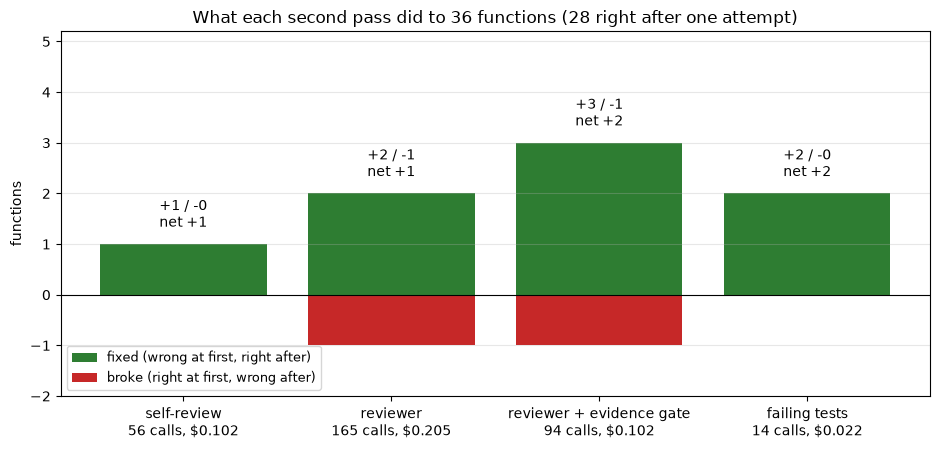

In [10]:
print(f"{'':26}{'pass':>6}{'fixed':>7}{'broke':>7}{'changed a':>11}{'approved a':>12}{'calls':>7}{'cost':>8}")
print(f"{'':26}{'':>6}{'':>7}{'':>7}{'right one':>11}{'wrong one':>12}{'':>7}{'':>8}")
n1, usd1 = cost("one attempt")
print(f"{'one attempt':26}{sum(first_ok):>6}{'':>7}{'':>7}{'':>11}{'':>12}{n1:>7}{'$' + format(usd1, '.3f'):>8}")
for r in ROWS:
    print(f"{r['arm']:26}{r['pass']:>6}{r['fixed']:>7}{r['broke']:>7}{r['changed_right']:>11}{r['approved_wrong']:>12}"
          f"{r['calls']:>7}{'$' + format(r['usd'], '.3f'):>8}")
n_all, usd_all = cost()
print(f"\nWhole notebook: {n_all} model calls, ${usd_all:.3f}, {time.time() - T0:.0f} seconds")

from matplotlib.ticker import MaxNLocator
fig, ax = plt.subplots(figsize=(9.5, 4.6))
x = list(range(len(ROWS)))
ax.bar(x, [r["fixed"] for r in ROWS], color="#2e7d32", label="fixed (wrong at first, right after)")
ax.bar(x, [-r["broke"] for r in ROWS], color="#c62828", label="broke (right at first, wrong after)")
for i, r in enumerate(ROWS):
    net = r["fixed"] - r["broke"]
    ax.text(i, r["fixed"] + 0.25, f"+{r['fixed']} / -{r['broke']}\nnet {net:+d}" if net else f"+{r['fixed']} / -{r['broke']}\nnet 0",
            ha="center", va="bottom", fontsize=10)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, [f"{r['arm']}\n{r['calls']} calls, ${r['usd']:.3f}" for r in ROWS])
ax.set_ylim(-max(r["broke"] for r in ROWS) - 1, max(r["fixed"] for r in ROWS) + 2.2)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylabel("functions")
ax.set_title(f"What each second pass did to {len(CASES)} functions ({sum(first_ok)} right after one attempt)")
ax.legend(loc="lower left", fontsize=9); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

### What the numbers say, and what they don't

- **Self-review without an outside signal did almost nothing, and said "correct" when it was not.** Net +1 here. Across this run and two earlier development runs (the same tickets and critics, with small differences in prompt wording and in how errors were reported), its net effect was +1, -1 and +1: noise around zero on this model. What did not change is the false confidence: here it approved 5 of the 7 functions still wrong at the end. Published results on self-correction without feedback point both ways, and this is one small data point, not a verdict.
- **A reviewer with nothing to check against invents work.** The ungated reviewer reported 143 problems on 36 functions, 28 of them correct, and when the same reviewer's findings were checked in section 6, nearly half (43 of 89) described behavior the code already had. Its net was +1 here. In the one earlier run that included it, it fixed 2 and broke 4, ending below the single attempt (26 against 28). It was also the most expensive critic.
- **The gate is cheap insurance, not a cure.** With the gate, the same reviewer changed 4 correct functions instead of 14, halved its cost, and tied the tests on pass count (30). In the two earlier runs it ended at 30 and 28 while the tests ended at 33 and 32, so the tie here is not the usual result.
- **The tests were the only critic that never broke a correct function,** here and in both earlier runs, and by far the cheapest: $0.022 here, against $0.102 to $0.205 for the model critics. Their limits are the two in section 7: they cannot fix a rule the model keeps misreading, and they pass whatever they do not test. Their net was +2 here against +5 and +4 earlier, partly because this run put three of its eight failures into `late_fee_cents`, the ticket the model kept misreading.
- **Small numbers.** 36 functions from 12 tickets, and the three samples of one ticket tend to fail the same way, so the effective sample is closer to 12 than to 36. Read any difference of one or two functions as noise. The model ran with `reasoning_effort="none"`. With reasoning on, both the first attempt and the self-review may do better; this notebook does not test that.

## 9. An aside: what "I reviewed it, it is correct" looked like

The self-review's verdicts are worth reading next to the tests. Here are functions it reviewed rule by rule and declared `correct`, with the hidden tests that disagree:

In [11]:
shown = 0
for name, o, ok in zip(CASES, self_outs, self_ok):
    if o["approved"] and not ok and shown < 4:
        shown += 1
        print(f"{name}: the self-review said `correct`, and the hidden tests say:")
        for msg in failures(name, o["code"], "hidden")[:2]:
            print("   ", msg)

shipping_cents: the self-review said `correct`, and the hidden tests say:
    shipping_cents(2000, 'world', False, 0) returned 2800, expected 2400
    shipping_cents(500, 'domestic', True, 9000) returned 1200, expected 1000
late_fee_cents: the self-review said `correct`, and the hidden tests say:
    late_fee_cents(date(2026, 3, 2), date(2026, 3, 20), 2000) returned 500, expected 400
format_names: the self-review said `correct`, and the hidden tests say:
    format_names(['Ana', 'Ben', 'Cy', 'Dee']) returned 'Ana, Ben and Cy and 1 other', expected 'Ana, Ben, Cy and 1 other'
    format_names(['A', 'B', 'C', 'D'], 2) returned 'A and B and 2 others', expected 'A, B and 2 others'
human_bytes: the self-review said `correct`, and the hidden tests say:
    human_bytes(3 * 1024**3) returned '3.0 TB', expected '3.0 GB'
    human_bytes(2048 * 1024**4) returned '2097152.0 TB', expected '2048.0 TB'


Each one is a rule misread or skipped, and the review repeated the same reading. The shipping function charges the first kilogram as an extra one. The late-fee function lets the minimum win over the cap. The `format_names` function joins the shown names with "and" before adding "and 1 other". The `human_bytes` function goes one unit too far. A second reading by the same model could not reveal these, because it reads the ticket the same way. One test run shows each of them.

## The fact to walk away with

A second pass is only as good as what its critic knows that the writer did not. The model rereading its own code knew nothing new: it moved the score by one function and approved most of what it left wrong. A fresh reviewer that could not run anything reported about four problems per function on code that was mostly correct, and when its findings were checked, nearly half described behavior the code already had. The failing tests knew the truth for the inputs they covered: they never broke a correct function in three runs, and cost a fraction of any model critic. Let code judge everything code can judge, put an evidence gate in front of any model reviewer, and before you keep a critique step, count the functions it fixes against the ones it breaks.

What to try next:

- **Turn reasoning on.** Set `reasoning_effort="low"` in `chat()` and rerun. A model that reasons may check its own work better, and the gap between self-review and tests may shrink. Watch the cost column.
- **Fix the ticket, not the loop.** Rewrite rule 4 of `late_fee_cents` as a formula, `min(max(fee, 500), cap)`, and see whether the three stuck functions go away. When one rule fails the same way across samples, the requirement is the bug.
- **Delete one rule's check tests** and watch the test loop approve functions that break that rule.
- **Combine the critics.** Run the tests first, and a gated reviewer only for what the tests cannot express, such as naming or readability, which this notebook does not score.

---
📖 **Want the decisions behind agents like this one, explained without code?** [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-agents-tutorials--reflection-from-scratch&click=book-nb-agents&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2%3Fmaas%3Dmaas_adg_api_580351185840460851_static_9_573%26ref_%3Daa_maas%26tag%3Dmaas%26aa_campaignid%3Dagents-en%26aa_adgroupid%3Dgithub-notebook%26aa_creativeid%3Dgenai-reflection&retarget=0&text=book-nb-agents) by the author of this repository has a full chapter on reflection: why self-critique is weak evidence, the four critics from weakest to strongest, the reflection budget, and the revision that breaks what passed. Available on Amazon.

![](https://europe-west1-genai-agents-views-tracker.cloudfunctions.net/genai-agents-tracker?notebook=all-agents-tutorials--reflection-from-scratch)